## Загрузка датасета

In [68]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer

data = fetch_20newsgroups(subset="all")
texts, y_true = data.data, data.target

## Эмбеддинг

In [69]:
vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(texts)

# Изменение размерности массива
Пробовал разные метрики для umap, с hellinger метрики кластеризации лучше

In [70]:
import umap

X_clust = umap.UMAP(n_components=20, metric="hellinger", min_dist=0.0).fit_transform(X)

# для отображения
X_umap = umap.UMAP(n_components=2).fit_transform(X)

/home/maxim/Desktop/PythonProjects/.venv/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:303: RuntimeWarning: invalid value encountered in sparse_correct_alternative_hellinger
  return super().__call__(*args, **kws)


## Кластеризуем 20 новостей
Пробовал разные методы кластерищации, с kmeans метрики лучше

In [71]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

k_means = KMeans(n_clusters=20).fit_predict(X_clust)

print("ARI:", adjusted_rand_score(y_true, k_means))
print("NMI:", normalized_mutual_info_score(y_true, k_means))

ARI: 0.42912228276586306
NMI: 0.5848776321723688


## Визуализация результатов кластеризации по сравнению с актуальным распределением

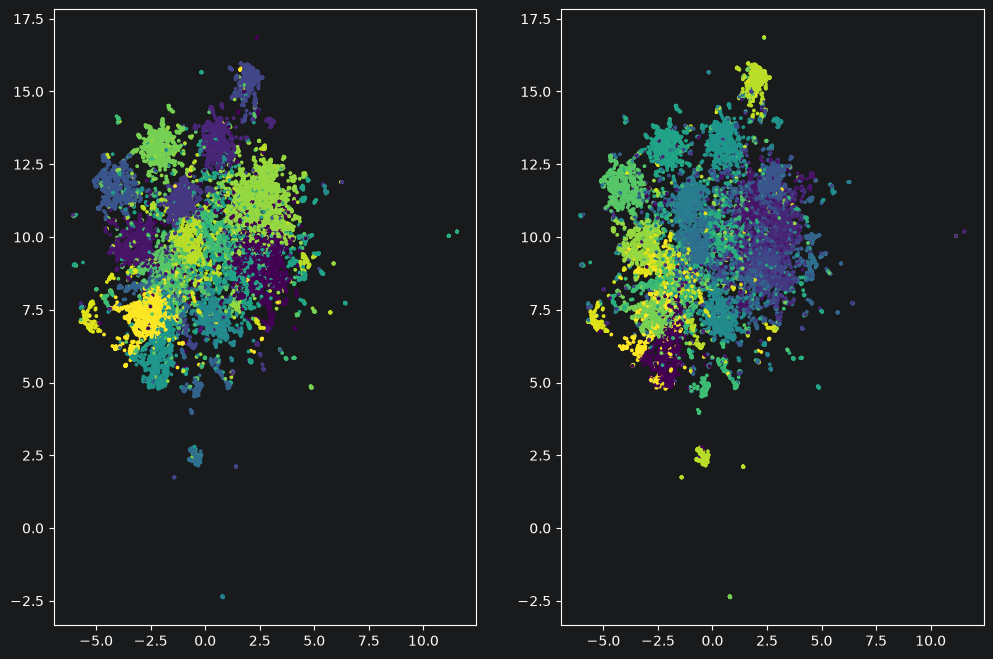

In [72]:
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=k_means, s=3)
plt.subplot(1, 2, 2)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_true, s=3)
plt.show()